# Quantum Metal A.6 — hackathon chip (South Korea 2020): two charge-line pockets with a direct coupling line (Quantcore PDK rebuild)

**What the chip is.** The exercise chip of the Qiskit Metal hackathon (South Korea 2020),
`docs/circuit-examples/full-design-flow-examples/A.6-Hackathon-exercise-South-Korea-2020.ipynb` (© IBM / Qiskit
Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/A6_hackathon_2q.md`): two `TransmonPocketCL`s 1.4 mm apart (Q2 rotated 180°), joined by a short
non-resonant line between their `bus` pads. Each qubit has a λ/2 readout from its `readout` pad through a 3-finger
`Cap3Interdigital` series capacitor to an edge `LaunchpadWirebond`, and a charge line from a south (Q1) or north (Q2)
launchpad into its `Charge_Line` pin. The source detunes the two qubits (`hfss_inductance` 14 / 12 nH). We distribute
the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the Metal
components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 9 × 6 mm centred on (0, 0) | the same 9 × 6 mm box (it does not fit the 7.5 mm die), shifted by (+4.5, +3) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 4 `LaunchpadWirebond`s, outer edge 740 µm (readout, E/W) and 240 µm (charge, S/N) in | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junctions | Metal junction line, `hfss_inductance` 14 / 12 nH (`Fake_Junctions` GDS) | Quantcore Nb/AlOx/Nb trilayer junctions, the 14 : 12 ratio kept round the PDK nominal: 7.25 / 6.22 nH (R_n 48.9 / 41.7 kΩ) |
| cheese | Metal's GDS cheese (exported with `no_cheese.buffer` 50 µm: 25 µm squares every 100 µm over the free ground) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule(buffer=50)`) |
| routes | `RoutePathfinder` lines, `RouteMeander` readouts 5.0 / 6.0 mm | qcc `cpw` routes on the same pins; qcc meanders of the same lengths (turn radius 99 µm = Metal's fillet) |
| placement | as drawn | content centred in the die |

**Kept exactly:** both qubits with the tutorial's options (pad width 425 µm, pocket 650 µm, `cl_pocket_edge` 180,
`readout` (+1, +1) and `bus` (−1, −1) pads), the caps (`finger_length` 40 µm, orientations ±90°), the four
launchpads and their positions along the edges, the readout lengths (5.0 / 6.0 mm), the 10/6 µm CPW and the 99 µm
fillet.

**Simplified:** Metal's `RoutePathfinder` lines (bus, pad lines, charge lines) become qcc `cpw` routes with the same
end pins (one Z or one elbow each); the readouts' `RouteMeander`s keep their end pins and total lengths but run as a
U through the free chip half above Q1 (below Q2) with a small meander, instead of Metal's two tall lobes between the
qubit and its cap (a symmetric qcc meander there would cross the charge line).

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 9 × 6 mm box gets the QCT frame; the four launchpads go 100 µm from the east, west, south and north edges; both qubits get trilayer junctions sized round the PDK nominal; the cheese is the original's (Metal's GDS cheese), drawn by the build instead of the PDK band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position is shifted by `(X0, Y0)` = half the chip (`P(x, y)`).

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (step 14), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule(buffer=50)}` hands the build Metal's rule (25 µm squares every 100 µm, 50 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`).

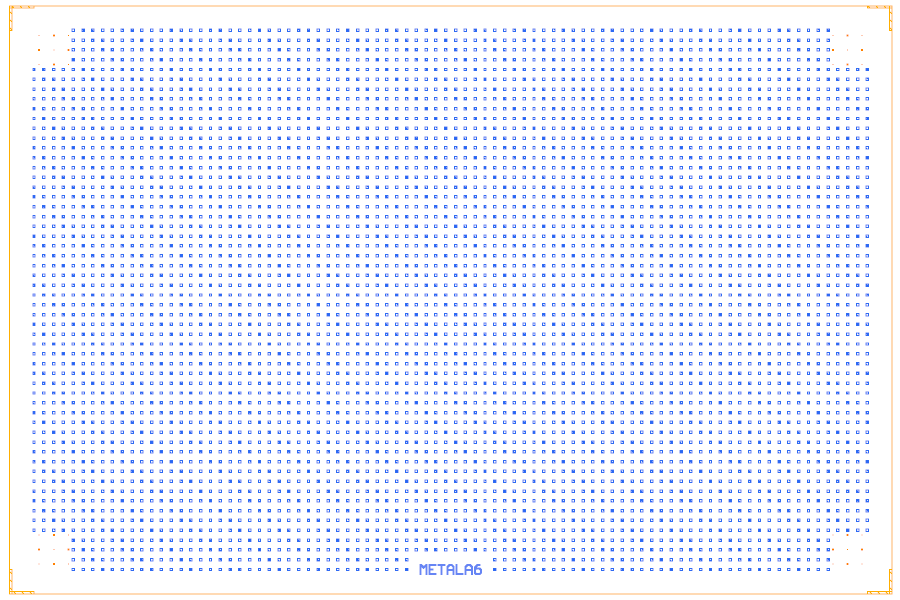

WindowsPath('examples/designs/metal/a6_hackathon_2q_step_die.png')

In [4]:
d = Designer("a6_hackathon_2q", box=(0, 0, 9000, 6000), chip={"name_chip": "MetalA6", "cheese": metal_cheese_rule(buffer=50)},
             live=LIVE)
X0, Y0 = 4500, 3000                              # Metal's 9 × 6 mm DesignPlanar chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
R = 99                                           # Metal fillet
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "a6_hackathon_2q_step_die.png", size=(900, 600), width=450)

## 4 · Pads: the PDK pad rule

The tutorial puts its readout launchpads at x = ±3.5 mm (740 µm from the east / west edges) and its charge-line
launchpads at y = ∓2.5 mm (240 µm from the south / north edges). In the Quantcore PDK the outer edge of every bond
pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**, whatever the source did: `edge="e"` / `"w"` /
`"s"` / `"n"` slides each pad perpendicular to that edge until it is there; its position along the edge is kept, so
the lines that leave a pad along its axis only get longer. The table measures it on the built layout.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| Launch_Q1_Read | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| Launch_Q2_Read | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| Launch_Q1_CL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_Q2_CL | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |

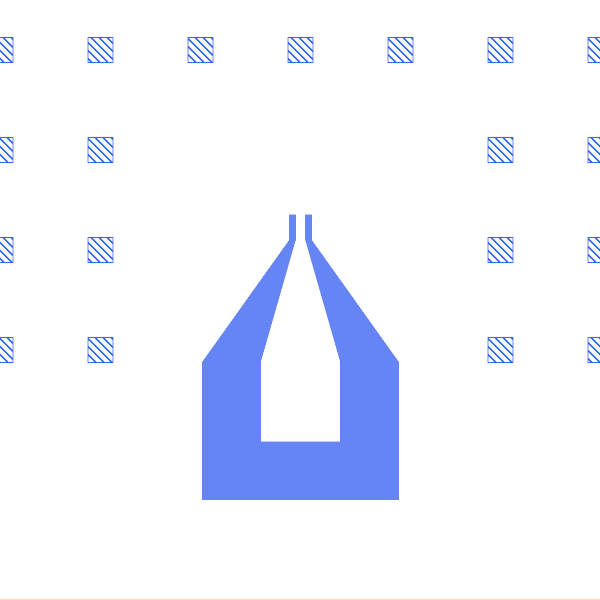

WindowsPath('examples/designs/metal/a6_hackathon_2q_step_pads.png')

In [5]:
with d.batch():
    l1r = d.add("Launch_Q1_Read", "metal:LaunchpadWirebond", at=P(3500, 0), rot=180, edge="e")
    l2r = d.add("Launch_Q2_Read", "metal:LaunchpadWirebond", at=P(-3500, 0), rot=0, edge="w")
    l1c = d.add("Launch_Q1_CL", "metal:LaunchpadWirebond", at=P(1350, -2500), rot=90, edge="s")
    l2c = d.add("Launch_Q2_CL", "metal:LaunchpadWirebond", at=P(-1350, 2500), rot=-90, edge="n")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "Launch_Q1_CL.tie")
snap(d, OUT / "a6_hackathon_2q_step_pads.png", box=(px - 300, 0, px + 300, 600), size=(600, 600), width=300)

## 5 · Components: the qubits and the readout capacitors

**The qubits.** `metal:TransmonPocketCL` is Metal's pocket transmon with a charge-line pin (`Charge_Line`), drawn by
the wrapper with the tutorial's options: two 425 µm pads in a 650 µm pocket, a `readout` pad at the upper right and
a `bus` pad at the lower left. Q2 is the same cell rotated 180°.

**The junctions.** The source detunes the qubits with `hfss_inductance` 14 / 12 nH (no target frequency). The
rebuild keeps that 14 : 12 ratio round the PDK nominal L_J (6.73 nH, R_n 45 kΩ): `trilayer_junction(..., lj_nH=)`
sizes a Quantcore trilayer junction for each (Q1 7.25 nH, R_n 48.9 kΩ; Q2 6.22 nH, R_n 41.7 kΩ: both in the
40–50 kΩ window) and returns the drawn junction's L_J and C_J for the LOM and the FEM junction port (`junction=`).

**The capacitors.** `metal:Cap3Interdigital` (3 fingers, 40 µm) is the series capacitor between each readout and its
pad line: the readout is a λ/2 between the qubit's pad and the capacitor.

Q1 {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 7.252430769230769}} {'Lj_nH': 7.32, 'Cj_fF': 13.8} 
Q2 {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 6.216369230769231}} {'Lj_nH': 6.2356, 'Cj_fF': 16.2}
Q1 ports: ['Charge_Line', 'bus', 'readout', 'squid_a', 'squid_b'] | Cap_Q1 ports: ['a', 'b']


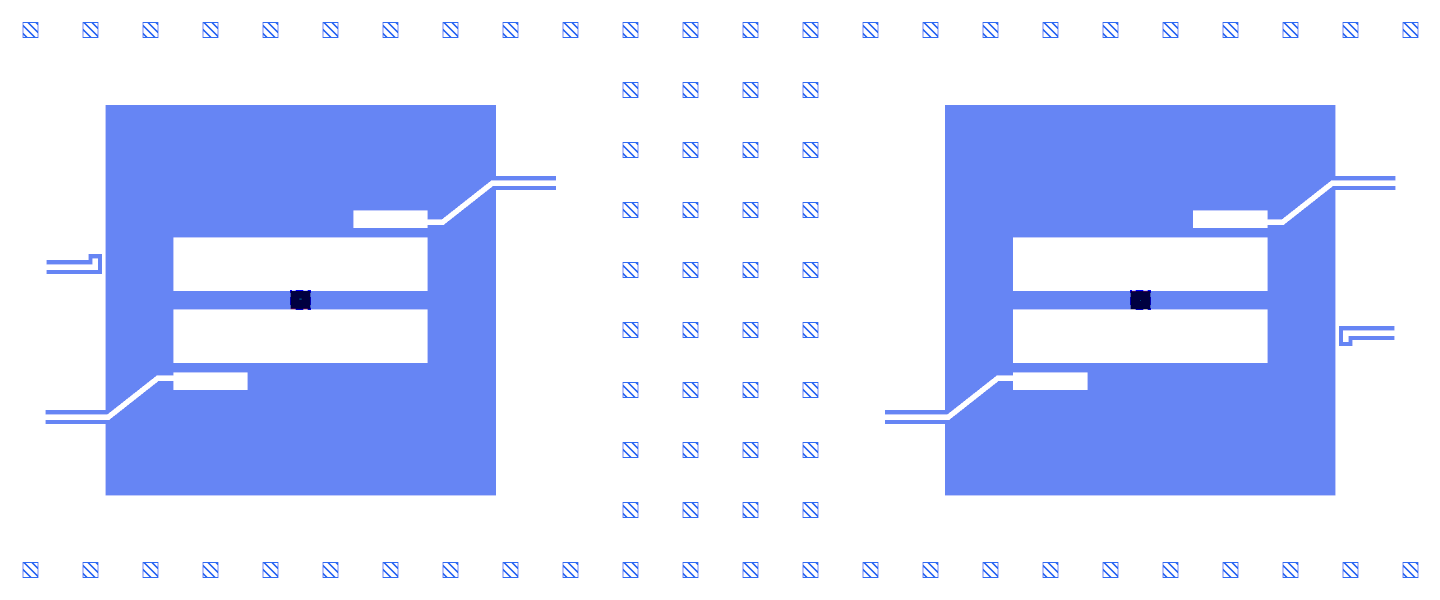

WindowsPath('examples/designs/metal/a6_hackathon_2q_step_parts.png')

In [6]:
# Quantcore trilayer junctions on the PDK rule (Nb Δ 1.4 meV). The source detunes Q1 / Q2 with hfss_inductance
# 14 / 12 nH; the rebuild keeps that ratio around the PDK nominal L_J 6.73 nH (R_n 45 kΩ): 7.25 / 6.22 nH,
# R_n 48.9 / 41.7 kΩ, both in the 40–50 kΩ window
LJ_PDK = trilayer_junction("metal:TransmonPocketCL")[1]["Lj_nH"]
JJP_Q1, JJ_Q1 = trilayer_junction("metal:TransmonPocketCL", lj_nH=LJ_PDK * 14 / 13)
JJP_Q2, JJ_Q2 = trilayer_junction("metal:TransmonPocketCL", lj_nH=LJ_PDK * 12 / 13)
print("Q1", JJP_Q1, JJ_Q1, "\nQ2", JJP_Q2, JJ_Q2)
with d.batch():
    pocket = dict(pad_width=425, pocket_height=650, cl_pocket_edge=180,
                  connection_pads={"readout": {"loc_W": 1, "loc_H": 1}, "bus": {"loc_W": -1, "loc_H": -1}})
    q1 = d.add("Q1", "metal:TransmonPocketCL", at=P(700, 0), junction=JJ_Q1, **JJP_Q1, **pocket)
    q2 = d.add("Q2", "metal:TransmonPocketCL", at=P(-700, 0), rot=180, junction=JJ_Q2, **JJP_Q2, **pocket)
    c1 = d.add("Cap_Q1", "metal:Cap3Interdigital", at=P(2500, 250), rot=90, finger_length=40)
    c2 = d.add("Cap_Q2", "metal:Cap3Interdigital", at=P(-2500, -250), rot=-90, finger_length=40)
print("Q1 ports:", sorted(q1.ports), "| Cap_Q1 ports:", sorted(c1.ports))
snap(d, OUT / "a6_hackathon_2q_step_parts.png", box=(3300, 2500, 5700, 3500), size=(1440, 600), width=640)

## 6 · Routes: coupling line, readouts, pad lines and charge lines

- **Coupling line:** `Bus_Q1_Q2` joins the two `bus` pads directly (a short, non-resonant line: a capacitive
  qubit–qubit coupling, no bus resonator).
- **Readouts:** `meander=5000` / `6000` make fixed-length λ/2 lines from each qubit's `readout` pad to its series
  capacitor; the waypoints run them as a U through the free half of the chip. Q2's path is the point mirror of
  Q1's through the chip centre, as in the source.
- **Pad lines and charge lines:** plain `cpw` routes from each launchpad to its capacitor or to the qubit's
  `Charge_Line` pin; each leaves its pad along the pad axis, so moving the pad to the edge only lengthens it.
- **Sim groups:** the two qubits with the coupling line (C-matrix), and each qubit with its readout and capacitor
  (C-matrix and eigenmode).

route lengths (µm): {'Bus_Q1_Q2': 855, 'Readout_Q1': 5000, 'Readout_Q2': 6000, 'TL_Q1': 1715, 'TL_Q2': 1715, 'TL_Q1_CL': 2751, 'TL_Q2_CL': 2751}


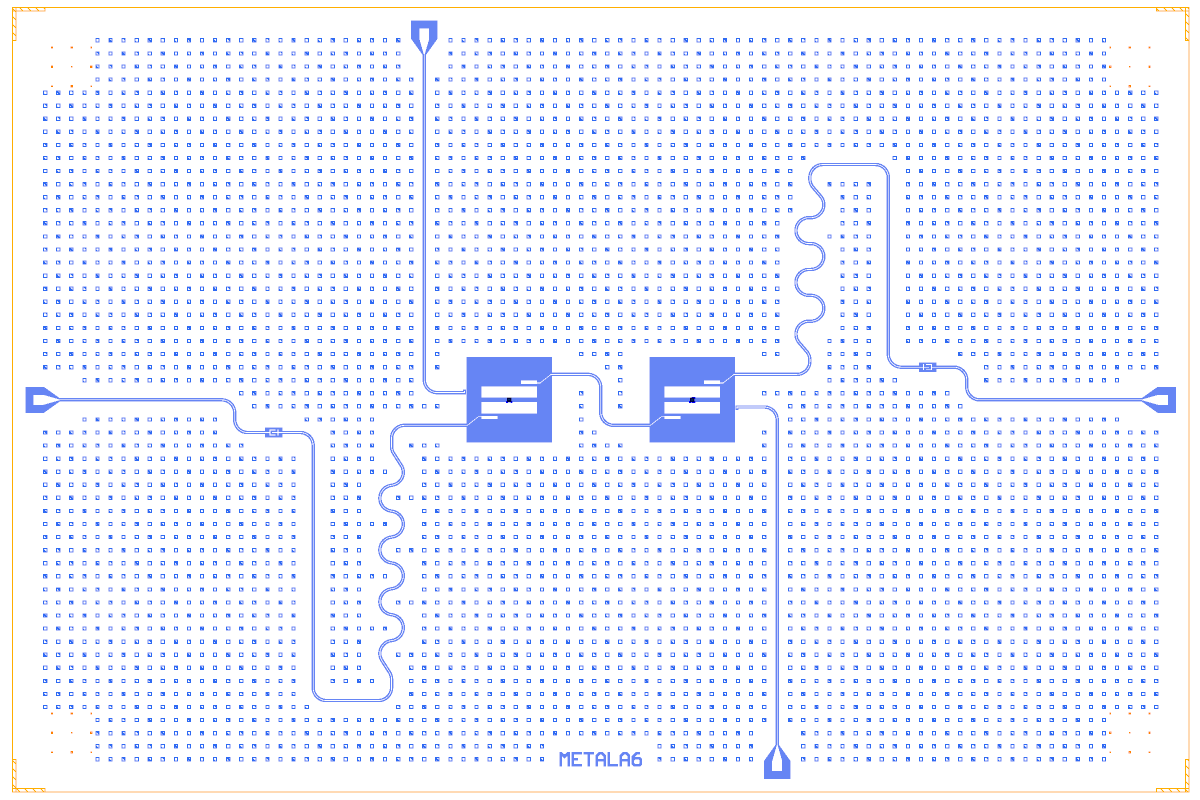

WindowsPath('examples/designs/metal/a6_hackathon_2q_step_routes.png')

In [7]:
with d.batch():
    # the direct (non-resonant) coupling line between the two bus pads
    d.route("Bus_Q1_Q2", q1.bus, q2.bus, r=R, nodes=[(4500, 2805), (4500, 3195)])
    # λ/2 readouts (pad → 3-finger series cap); Q2's path is the point mirror of Q1's through the chip centre
    M = lambda pts: [(2 * X0 - x, 2 * Y0 - y) for x, y in pts]
    d.route("Readout_Q1", q1.readout, c1.a, meander=5000, r=R, nodes=[(6100, 3195), (6100, 4800), (6700, 4800), (6700, 3250)])
    d.route("Readout_Q2", q2.readout, c2.a, meander=6000, r=R, nodes=M([(6100, 3195), (6100, 5300), (6700, 5300), (6700, 3250)]))
    d.route("TL_Q1", l1r.tie, c1.b, r=R, nodes=[(7300, 3000), (7300, 3250)])
    d.route("TL_Q2", l2r.tie, c2.b, r=R, nodes=M([(7300, 3000), (7300, 3250)]))
    # charge lines into the TransmonPocketCL Charge_Line pins
    d.route("TL_Q1_CL", l1c.tie, q1.Charge_Line, r=R, nodes=[(5850, 2945)])
    d.route("TL_Q2_CL", l2c.tie, q2.Charge_Line, r=R, nodes=[(3150, 3055)])
# FEM boxes: margins chosen so that each box cuts every other line once
d.sim_group("Q1_Q2", ["Q1", "Q2", "Bus_Q1_Q2"], margin_um=150, analyses=["q3d_cmatrix"])
for k in (1, 2):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"Readout_Q{k}", f"Cap_Q{k}"], margin_um=150, analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "a6_hackathon_2q_step_routes.png", size=(1200, 800), width=480)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). With pads on all four edges and the point-symmetric layout, nothing should move. Then
the design is saved: the JSON is the deliverable.

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN = d.save(OUT / "a6_hackathon_2q.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm
<Designer a6_hackathon_2q: 8 instances, 7 routes, live=False> → examples\designs\metal\a6_hackathon_2q.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, four `dangling_port` warnings (`Q1`/`Q2` `squid_a` / `squid_b`, the junctions'
attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings**: the pads are at 100 µm, both junctions are inside the 40–50 kΩ R_n window, and the source states no
target frequency.

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 4 | Q1.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 25, gap 75, rows 1000, clearance 50, edge 200 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 2 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: a `TransmonPocketCL` gives two floating pad nodes with the junction
between them, a node per connection pad, and the `Charge_Line` as a drive port (a small capacitance to the near pad).
The two `bus` pads are joined by the short coupling line (one node, no resonance in band); each readout between a
pad and a series capacitor to a 50 Ω launchpad port is a λ/2 `TLres`. The port map shows where Q1's ports landed.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "Cap_Q1."))})

**12 nodes · 34 branches · 2 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Cap_Q1.b` | `Launch_Q1_Read.pad`, `Cap_Q1.b` |
| `Cap_Q2.b` | `Launch_Q2_Read.pad`, `Cap_Q2.b` |
| `Launch_Q1_CL.pad` | `Launch_Q1_CL.pad` |
| `Launch_Q2_CL.pad` | `Launch_Q2_CL.pad` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.readout` | `Q1.readout`, `Cap_Q1.a` |
| `Q1.bus` | `Q1.bus`, `Q2.bus` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.readout` | `Q2.readout`, `Cap_Q2.a` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_Launch_Q1_Read` | R | `Cap_Q1.b` – `gnd` | 50 Ω |
| `Port_Launch_Q2_Read` | R | `Cap_Q2.b` – `gnd` | 50 Ω |
| `Port_Launch_Q1_CL` | R | `Launch_Q1_CL.pad` – `gnd` | 50 Ω |
| `Port_Launch_Q2_CL` | R | `Launch_Q2_CL.pad` – `gnd` | 50 Ω |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 34.3 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 34.3 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 26.2 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 7.32 nH, Cj 13.8 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 17 fF |
| `Cf_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 1.8 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 34.3 fF |
| `Cg_Q1_bus` | C | `Q1.island2` – `Q1.bus` | 17 fF |
| `Cf_Q1_bus` | C | `Q1.island1` – `Q1.bus` | 1.8 fF |
| `Cc_Q1_bus` | C | `Q1.bus` – `gnd` | 34.3 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 34.3 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 34.3 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 26.2 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.24 nH, Cj 16.2 fF |
| `Cg_Q2_readout` | C | `Q2.island1` – `Q2.readout` | 17 fF |
| `Cf_Q2_readout` | C | `Q2.island2` – `Q2.readout` | 1.8 fF |
| `Cc_Q2_readout` | C | `Q2.readout` – `gnd` | 34.3 fF |
| `Cg_Q2_bus` | C | `Q2.island2` – `Q1.bus` | 17 fF |
| `Cf_Q2_bus` | C | `Q2.island1` – `Q1.bus` | 1.8 fF |
| `Cc_Q2_bus` | C | `Q1.bus` – `gnd` | 34.3 fF |
| `C_Cap_Q1` | C | `Q1.readout` – `Cap_Q1.b` | 4.86 fF |
| `C_Cap_Q1_a` | C | `Q1.readout` – `gnd` | 4.8 fF |
| `C_Cap_Q1_b` | C | `Cap_Q1.b` – `gnd` | 4.8 fF |
| `C_Cap_Q2` | C | `Q2.readout` – `Cap_Q2.b` | 4.86 fF |
| `C_Cap_Q2_a` | C | `Q2.readout` – `gnd` | 4.8 fF |
| `C_Cap_Q2_b` | C | `Cap_Q2.b` – `gnd` | 4.8 fF |
| `Cd_Q1` | C | `Q1.island1` – `Launch_Q1_CL.pad` | 0.1 fF |
| `Cd_Q2` | C | `Q2.island1` – `Launch_Q2_CL.pad` | 0.1 fF |
| `Readout_Q1` | TLres | `Q1.readout` – `gnd` | lambda/2, 5000 µm, 12.603 GHz |
| `Readout_Q2` | TLres | `Q2.readout` – `gnd` | lambda/2, 6000 µm, 10.503 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `TL_Q1_CL` | drive | `J_Q1` | `TL_Q1_CL` | 2751 |
| `TL_Q2_CL` | drive | `J_Q2` | `TL_Q2_CL` | 2751 |

**Unconnected ports:** none

{'Q1.squid_a': 'Q1.island2', 'Q1.squid_b': 'Q1.island1', 'Q1.readout': 'Q1.readout', 'Q1.bus': 'Q1.bus', 'Q1.Charge_Line': 'control:drive', 'Cap_Q1.a': 'Q1.readout', 'Cap_Q1.b': 'Cap_Q1.b'}


## 10 · LOM simulation

Each qubit with its readout, capacitor, pad line and launchpad (both charge lines are 50 Ω loads); then the two
qubits with the coupling line (QuCat normal modes and the static ZZ from QuTiP). With the PDK-sized junctions the
qubits sit near 7.0 / 7.4 GHz (the source's 14 / 12 nH gave 5.42 / 5.89 GHz); the tutorial states no targets, so
the comparison is with the PDK band (4–8 GHz) and the source's detuning, which is kept.

In [11]:
read = {f"Q{k}+read": [f"Q{k}", f"Readout_Q{k}", f"Cap_Q{k}", f"TL_Q{k}", f"Launch_Q{k}_Read", f"TL_Q{k}_CL",
                       f"Launch_Q{k}_CL"] for k in (1, 2)}
results = simulate_groups(d, read)
display(Markdown(groups_md(results)))
pair = simulate_groups(d, {"Q1+Q2+bus": ["Q1", "Q2", "Bus_Q1_Q2"]})
display(Markdown("**Q1 + Q2 + coupling line, QuCat normal modes:**\n\n" + modes_md(pair["Q1+Q2+bus"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(pair)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+read | Q1 | 6.96 | -328.5 | Readout_Q1 | 11.696 | 2.42 | -1.63 |
| Q2+read | Q2 | 7.4348 | -311.3 | Readout_Q2 | 9.8665 | 1.47 | -3.39 |

**Q1 + Q2 + coupling line, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 7.3014 | 0 | 296.2 | J_Q1 1.00 |
| Q2 | qubit | 7.7721 | 0 | 285.9 | J_Q2 1.00 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q1+Q2+bus | Q1-Q2 | -6868 | yes | no |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

A **Q3D C-matrix** job for the two qubits with the coupling line (the tutorial's own Q3D + LOM step: it gives
the island capacitances and the qubit–qubit coupling C), and, per qubit, a C-matrix and an **eigenmode / EPR** job
with its readout and capacitor (lines leaving the box end in 50 Ω, so the mode Q gives κ).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN)
jobs_eig = export_sims(DESIGN, ["Q1_read", "Q2_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1_Q2 | `build/jobs/a6_hackathon_2q_Q1_Q2_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · waveguide · `Q1.bus`<br>4 · waveguide · `Q2.bus`<br>5 · edge · `Readout_Q1`<br>6 · edge · `Readout_Q2`<br>7 · edge · `TL_Q1_CL`<br>8 · edge · `TL_Q2_CL` | `Q1.island2`, `Q2.island2`, `Q1.bus`, `Q2.bus`, `Readout_Q1`, `Readout_Q2`, `TL_Q1_CL`, `TL_Q2_CL`, `Q2.island1`, `Q1.island1` |
| Q1_read | `build/jobs/a6_hackathon_2q_Q1_read_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.readout`<br>3 · waveguide · `Cap_Q1.a`<br>4 · edge · `Bus_Q1_Q2`<br>5 · edge · `TL_Q1`<br>6 · edge · `TL_Q1_CL` | `Q1.island2`, `Q1.readout`, `Cap_Q1.a`, `Bus_Q1_Q2`, `TL_Q1`, `TL_Q1_CL`, `Q1.island1` |
| Q2_read | `build/jobs/a6_hackathon_2q_Q2_read_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.readout`<br>3 · waveguide · `Cap_Q2.a`<br>4 · edge · `Bus_Q1_Q2`<br>5 · edge · `TL_Q2`<br>6 · edge · `TL_Q2_CL` | `Q2.island2`, `Q2.readout`, `Cap_Q2.a`, `Bus_Q1_Q2`, `TL_Q2`, `TL_Q2_CL`, `Q2.island1` |
| Q1_read | `build/jobs/a6_hackathon_2q_Q1_read_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `Bus_Q1_Q2`<br>3 · edge_lumped · `TL_Q1`<br>4 · edge_lumped · `TL_Q1_CL` | `Q1.island2`, `Bus_Q1_Q2`, `TL_Q1`, `TL_Q1_CL`, `Q1.island1`, `Q1.readout` |
| Q2_read | `build/jobs/a6_hackathon_2q_Q2_read_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `Bus_Q1_Q2`<br>3 · edge_lumped · `TL_Q2`<br>4 · edge_lumped · `TL_Q2_CL` | `Q2.island2`, `Bus_Q1_Q2`, `TL_Q2`, `TL_Q2_CL`, `Q2.readout`, `Q2.island1` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q1_Q2', 'Q1_read', 'Q2_read'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q1_Q2 · q3d, Q1_read · q3d, Q2_read · q3d, Q1_read · eigenmode, Q2_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q1's junction, from the detuned 7.25 nH back to the PDK nominal 6.73 nH (R_n
45 kΩ) — rebuild, re-run the LOM of Q1 with its readout and compare. A smaller L_J raises f_q (f_q ∝ 1/√(L_J C_Σ)),
which shrinks the qubit–readout detuning and the dispersive shift moves with it.

In [15]:
d2 = design_copy(DESIGN)
JJP_NOM, JJ_NOM = trilayer_junction("metal:TransmonPocketCL", lj_nH=LJ_PDK)
d2["Q1"].set(junction=JJ_NOM, **JJP_NOM)         # 7.25 → 6.73 nH (and the drawn finger with it)
after = simulate_groups(d2, {"Q1+read": read["Q1+read"]})
display(Markdown(params_delta_md({"Q1+read": results["Q1+read"]}, after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+read: Q1.f_q_GHz` | 6.96 | 7.2069 | +0.2469 |
| `Q1+read: Q1.alpha_MHz` | -328.47 | -320.39 | +8.079 |
| `Q1+read: Readout_Q1.chi_MHz` | -1.6267 | -1.7418 | -0.1151 |
| `Q1+read: Readout_Q1.f_GHz` | 11.696 | 11.696 | +0.0003758 |
| `Q1+read: Readout_Q1.kappa_MHz` | 2.4224 | 2.4221 | -0.0002821 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** The A.6 notebook exports its GDS with Metal's `QGDSRenderer`, whose cheese is on by default (`cheese.view_in_file = {main: {1: True}}`: 25 µm squares every 100 µm, `edge_nocheese` 200 µm), and sets `no_cheese.buffer = 50um`. So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (step 3: `metal_cheese_rule(buffer=50)` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\a6_hackathon_2q.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 4173 |
| 2/0 | JJ_STRAIGHT | 2 |
| 3/0 | M3 | 4165 |
| 4/0 | JJ_BENT | 2 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 4163 holes on the mask.

→ `build/a6_hackathon_2q_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's screenshot); the two qubits with the coupling line and the charge-line ends;
Q1's trilayer junction; the `Cap_Q1` interdigital capacitor; the **fab mask** round Q1 (1/0 etch with the
original's Metal cheese, the 3/0 keep-out, the junction layers); and the die frame's south-west corner (dicing L on
1000/0, alignment grid on 1001/0). Positions are read from the design (after the centring shift).

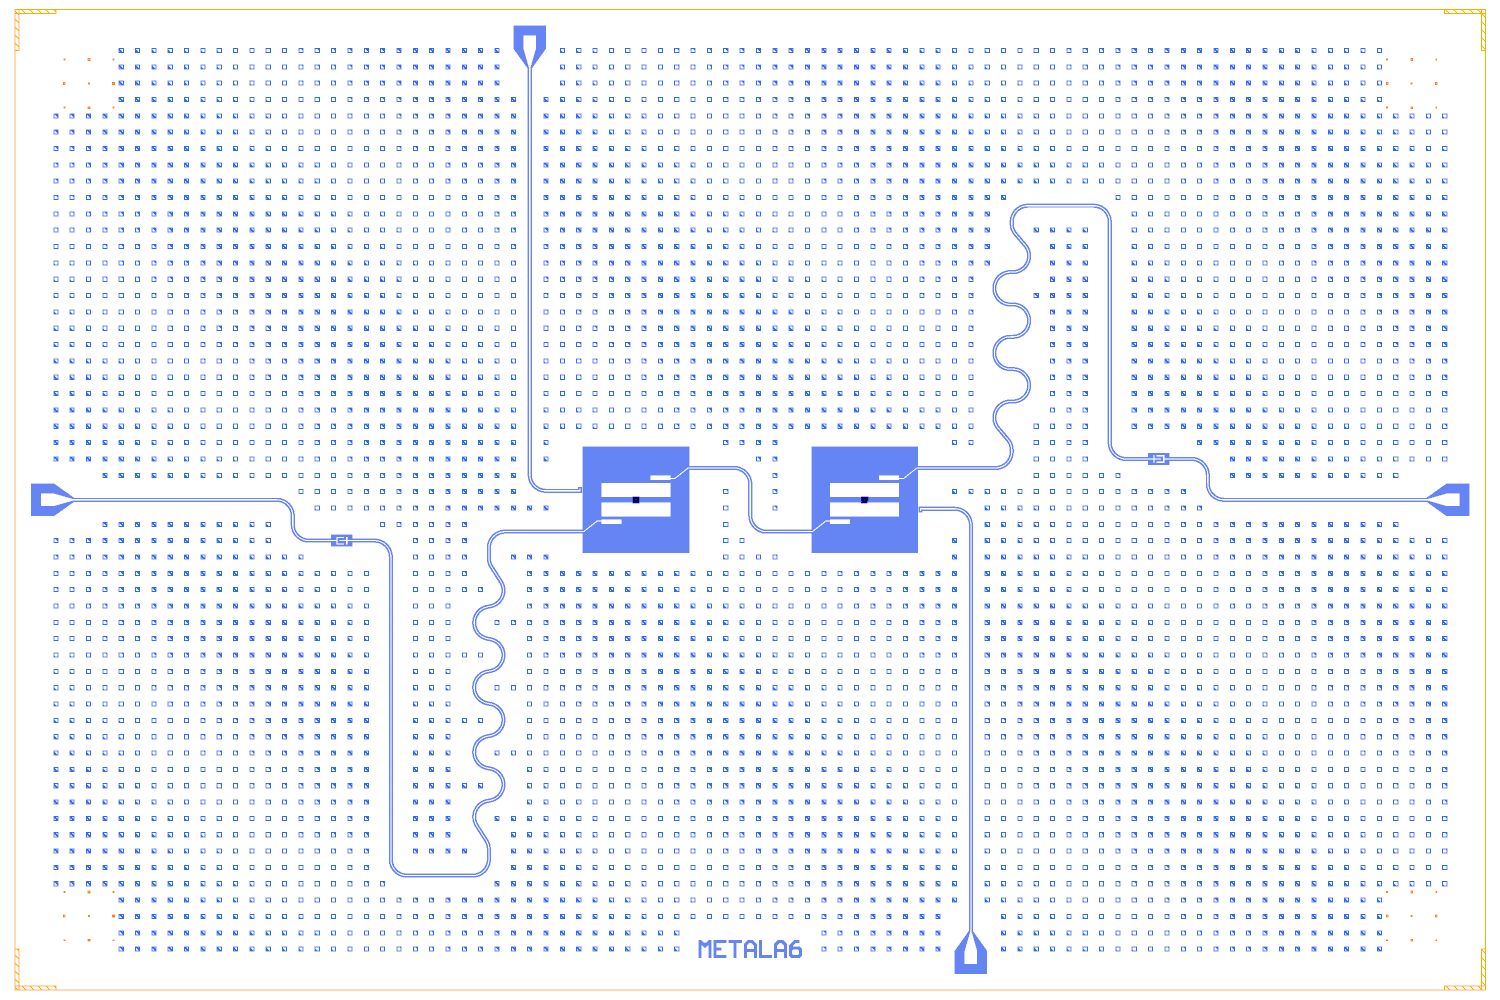

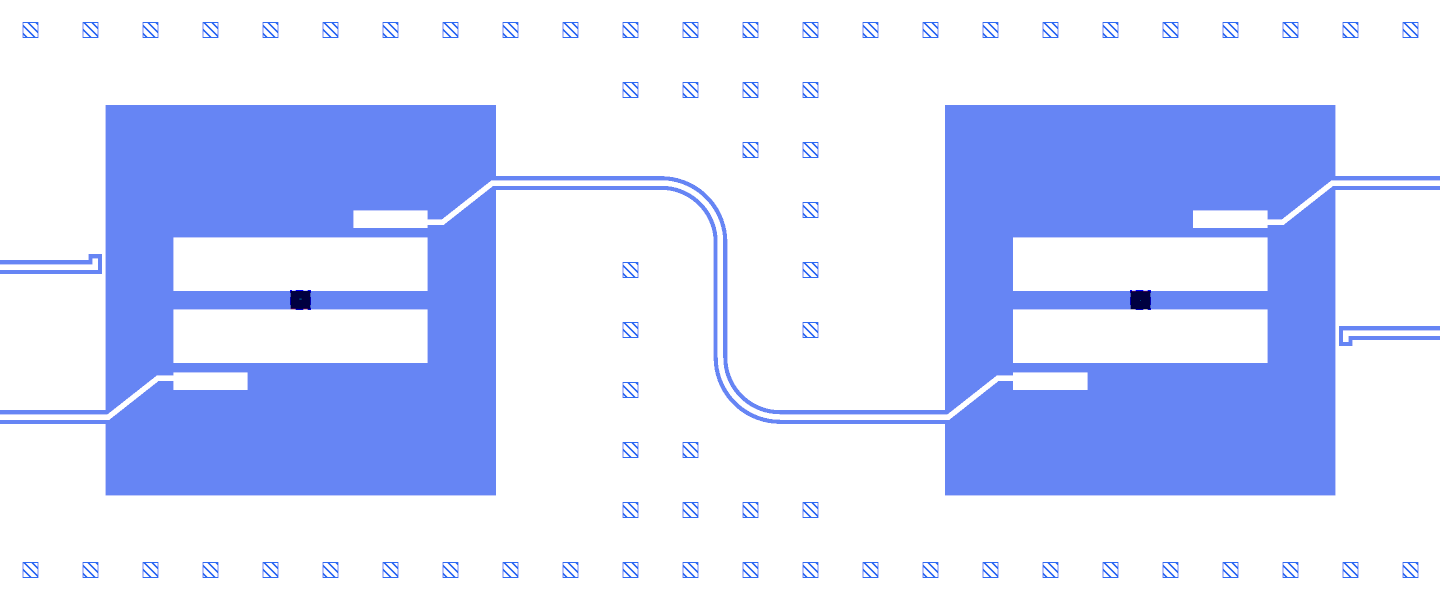

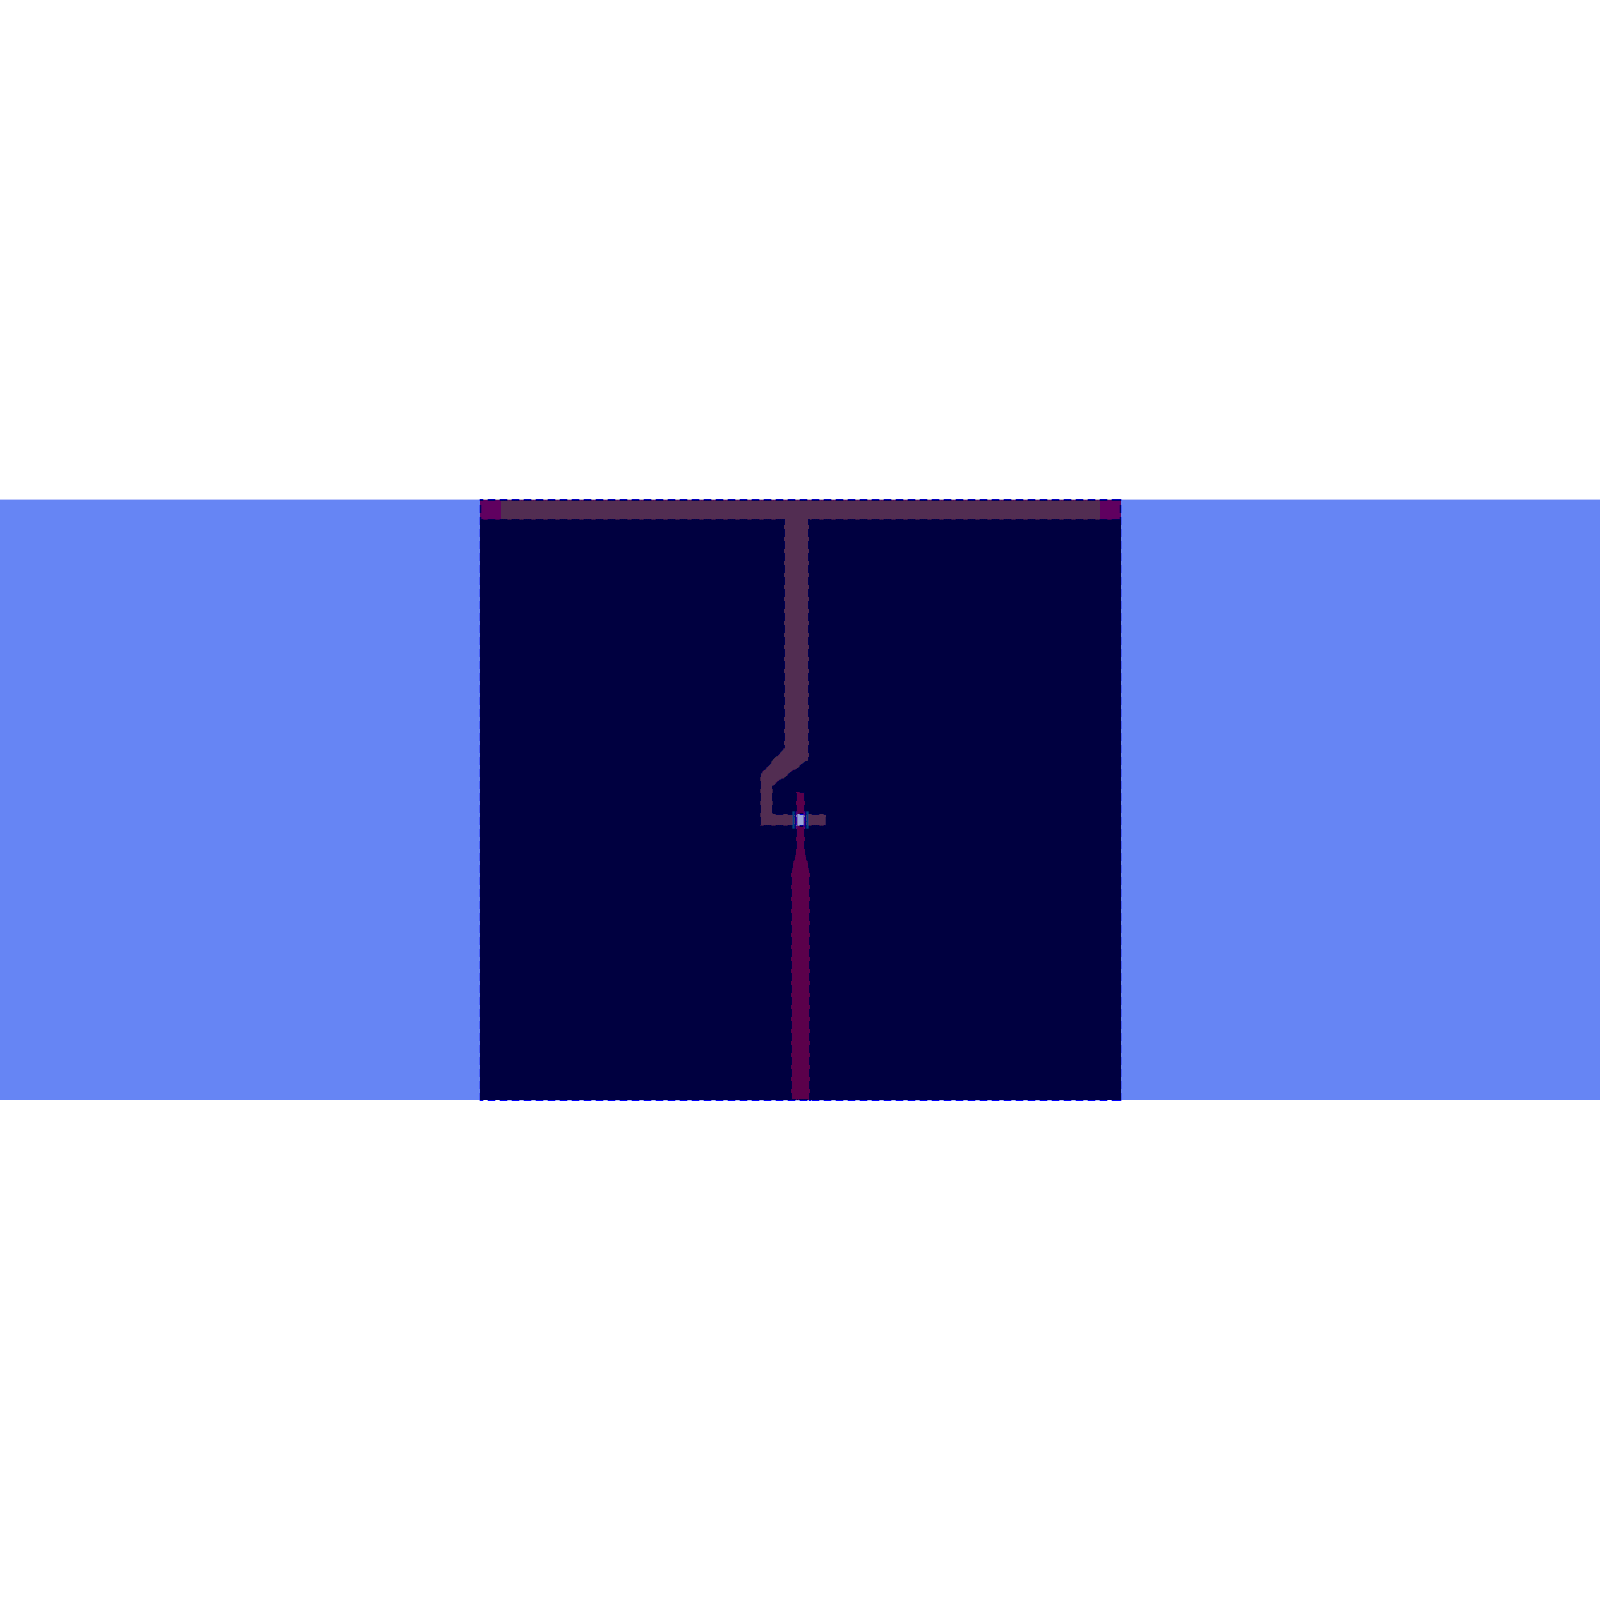

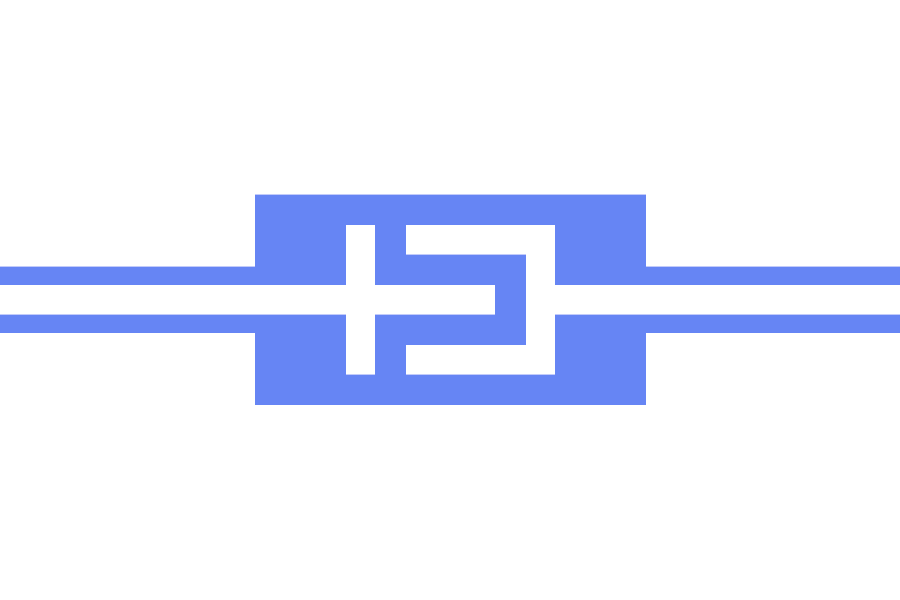

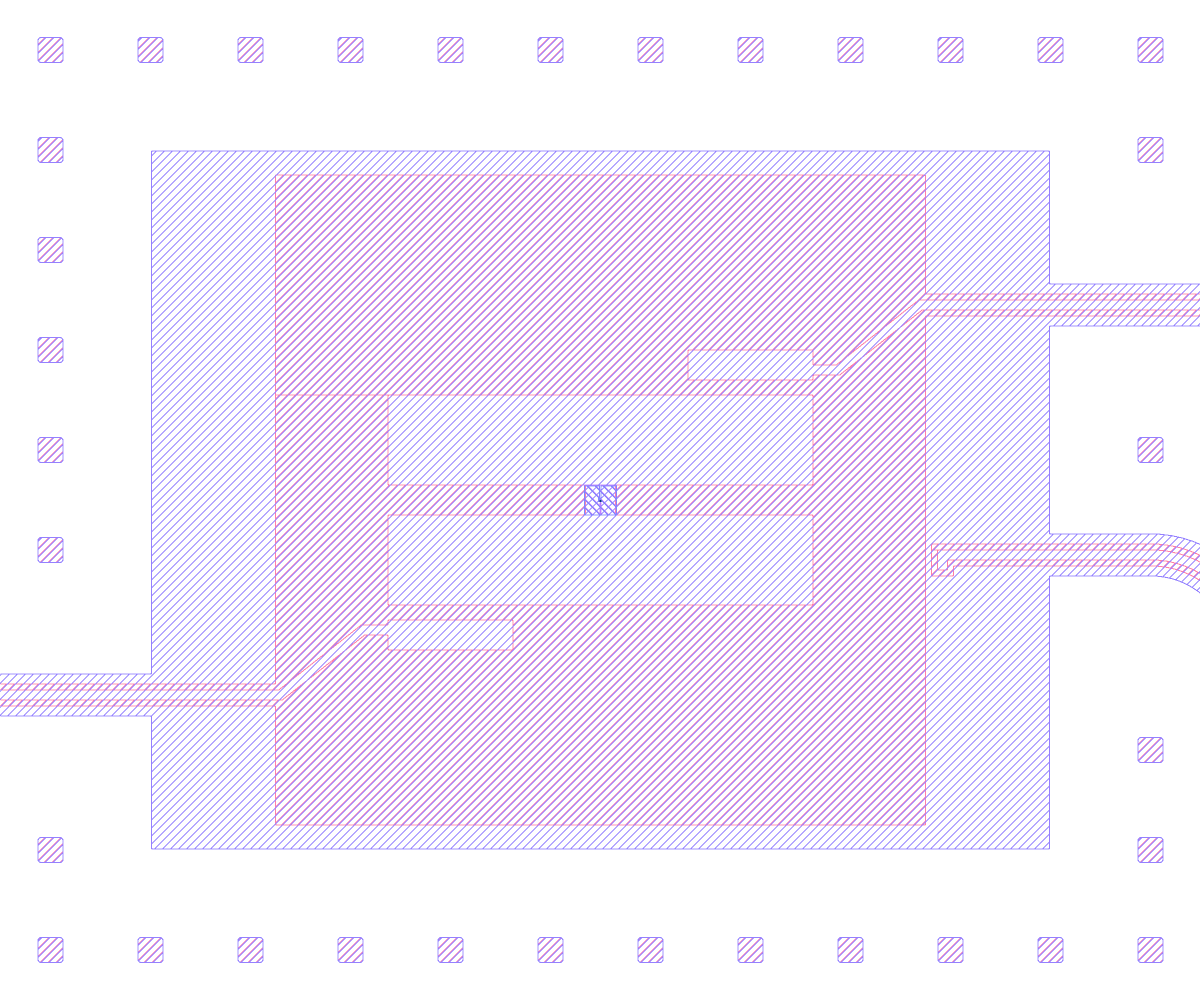

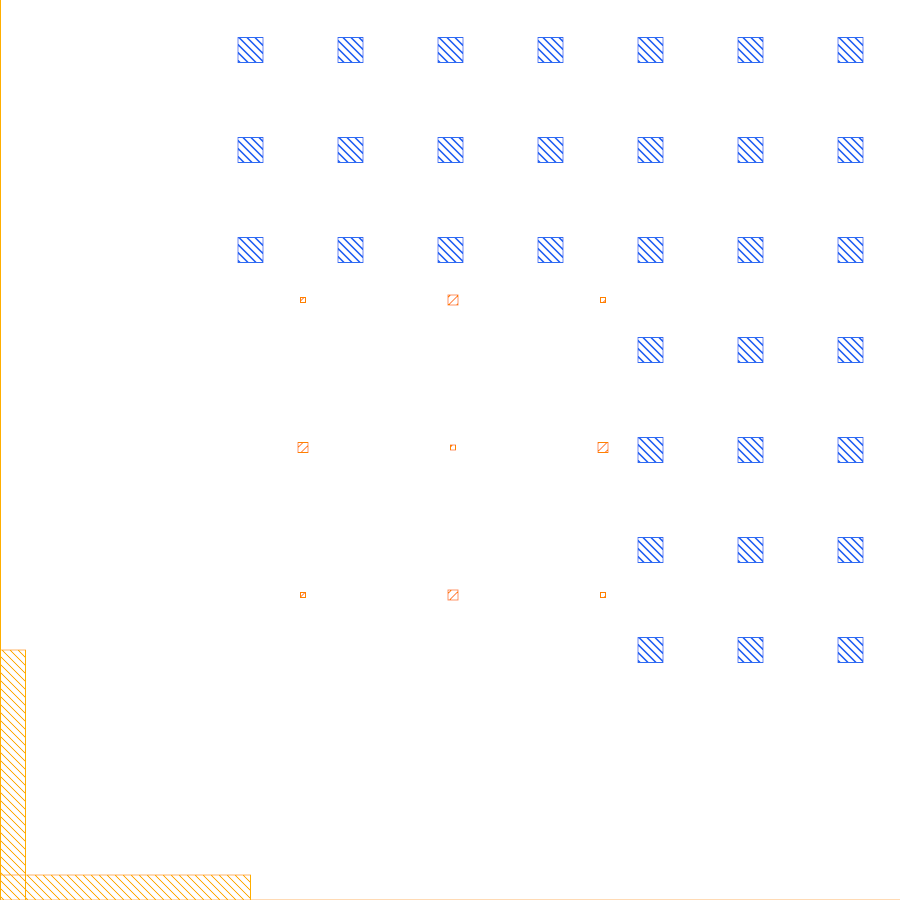

In [17]:
Q1X, Q1Y = d.data["instances"]["Q1"]["place"]["at"]
Q2X, Q2Y = d.data["instances"]["Q2"]["place"]["at"]
CX, CY = d.data["instances"]["Cap_Q1"]["place"]["at"]
mx, my = (Q1X + Q2X) / 2, (Q1Y + Q2Y) / 2
show_snapshot(d, OUT / "a6_hackathon_2q.png", size=(1500, 1000))
show_snapshot(d, OUT / "a6_hackathon_2q_qubits.png", box=(mx - 1200, my - 500, mx + 1200, my + 500), size=(1440, 600),
              width=640)
show_snapshot(d, OUT / "a6_hackathon_2q_jj.png", box=(Q1X - 40, Q1Y - 40, Q1X + 40, Q1Y + 40), width=300)
show_snapshot(d, OUT / "a6_hackathon_2q_cap.png", box=(CX - 150, CY - 100, CX + 150, CY + 100), size=(900, 600), width=360)
snap_file(Path("build") / "a6_hackathon_2q_fab.oas", OUT / "a6_hackathon_2q_cheese.png",
          box=(Q1X - 600, Q1Y - 500, Q1X + 600, Q1Y + 500), size=(1200, 1000), width=420)
show_snapshot(d, OUT / "a6_hackathon_2q_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins, the 5.0 / 6.0 mm readouts, the direct coupling line, the source's 14 : 12 junction detuning |
| PDK changes | QCT frame on the source's 9 × 6 mm box; sapphire stack; the four launchpads 100 µm from the edges (were 740 µm east / west, 240 µm south / north); trilayer junctions 7.25 / 6.22 nH (R_n 48.9 / 41.7 kΩ); cheese = the original's Metal cheese, drawn by the build; content centred (shift printed in step 7) |
| differs | the readout meanders' shape (qcc router); f_q 6.96 / 7.43 GHz, readouts 11.70 / 9.87 GHz (χ −1.6 / −3.4 MHz), Q1–Q2 ZZ ≈ −6.9 MHz with the PDK junctions (the source's 14 / 12 nH gave 5.42 / 5.89 GHz) |
| PDK design warnings | none |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`) |